# Write the science. Our compilers do the expert work.

Science runs on code that scientists write. Making that code fast, running it on GPUs and TPUs, or differentiating through it normally takes experts who rewrite and hand-tune it, often in another framework. Our open-source compiler stack ([EnzymeAD](https://github.com/EnzymeAD)) does this automatically, on the code that already exists, so scientists get expert-level performance without becoming performance experts.

| | |
|---|---|
| **Reactant** | compiles existing code for GPUs and TPUs, and optimizes it along the way |
| **Enzyme** | differentiates entire programs written in C, C++, Fortran, Rust, Julia, or Python |
| **Impulse** | builds probabilistic programming into the compiler: write the model the way the science reads, get fast inference with uncertainty |

## Setup

In [ ]:
if any(occursin("COLAB"), keys(ENV))
    using Downloads
    tok = get(ENV, "SAIL_GITHUB_TOKEN", "")
    include(Downloads.download("https://raw.githubusercontent.com/PRONTOLab/sail2026-demo/main/colab/colab_setup.jl";
        headers = isempty(tok) ? Pair{String, String}[] : ["Authorization" => "Bearer $tok"]))
end
include("demo_utils.jl")
prepare_demo!()

## Reactant: GPU and TPU speed without hardware expertise

Running on a GPU or TPU normally means rewriting code in CUDA or in an AI framework. With Reactant you add one line, `@jit`, and the compiler does the rest: it compiles the ordinary function for the hardware you have and optimizes it along the way.

In [2]:
f(x) = sum(abs2, sin.(x) .* exp.(-x .^ 2))    # ordinary Julia: nothing GPU-specific

x = rand(Float32, 10_000_000)                 # ten million numbers
x_gpu = Reactant.to_rarray(x)                 # the same numbers, on the GPU

@jit f(x_gpu)                                 # the one line you add

ConcretePJRTNumber{Float32, 1}(994258.25f0)

In [3]:
cpu_vs_gpu(f, x, x_gpu)

CPU:   130.75 ms   answer 994258
GPU:     0.05 ms   answer 994258


one added line: 2786× faster, same answer


### A real ocean model

[Oceananigans](https://github.com/CliMA/Oceananigans.jl) is an ocean model for climate research, written in Julia for NVIDIA GPUs. Its users pick the hardware when they build the grid; changing that one word to `ReactantState()` hands the whole model to Reactant:

```julia
grid  = RectilinearGrid(ReactantState(); size = (96, 96, 8), ...)   # was: RectilinearGrid(GPU(); ...)
model = HydrostaticFreeSurfaceModel(grid; ...)                      # Oceananigans, unchanged
@compile loop!(model, 50)                                           # 50 time steps, compiled
```

Below, a front between warm and cold water breaks into eddies, the process that fills the real ocean with them.

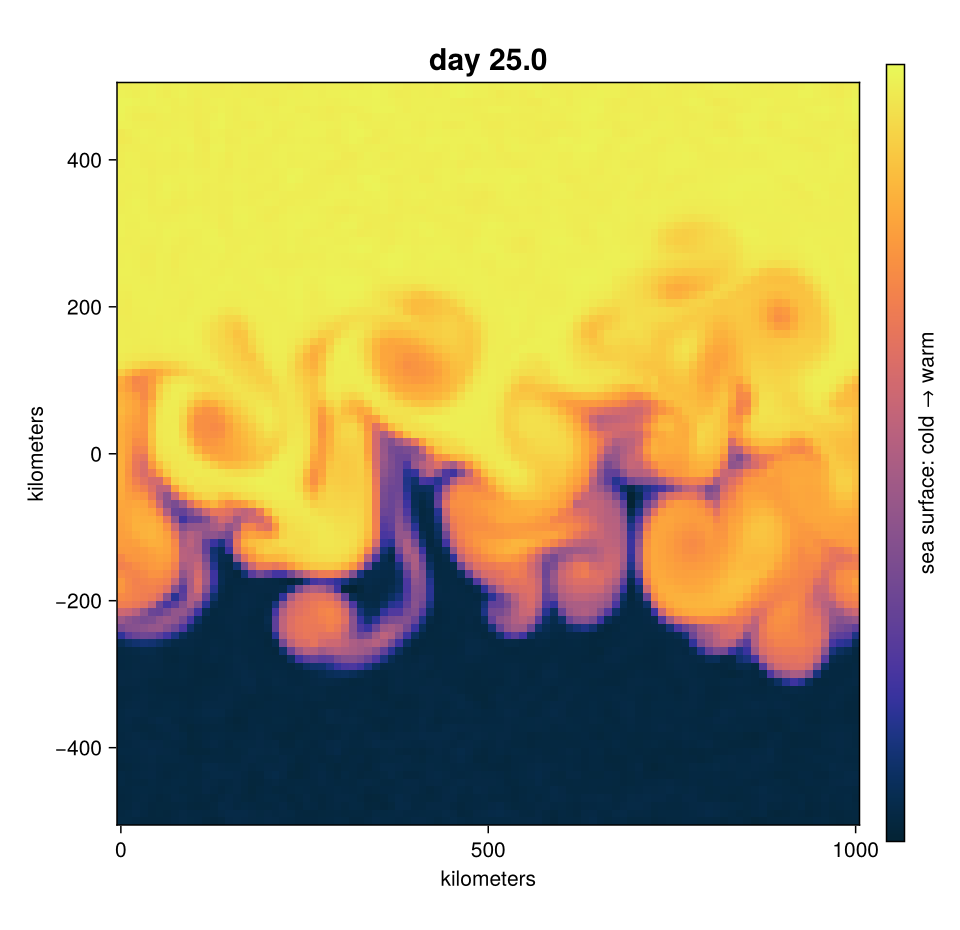

25 days of ocean, 1800 time steps: 1.3 s on one GPU


In [4]:
ocean_eddies!()

### At supercomputer scale

The same path runs Oceananigans across whole supercomputers ([GB-25](https://github.com/PRONTOLab/GB-25)). Reactant ran the model on **1,280 Google TPU chips**, which cannot run NVIDIA GPU code at all, and on **4,096 NVIDIA GPUs** of NERSC's Perlmutter. On Perlmutter, Reactant's optimizations made the model **10× to 100× faster** than the same compiled code without them, mostly by choosing a better way for the GPUs to communicate: tuning that HPC experts normally do by hand. Spreading a function across many devices takes two more lines:

```julia
mesh = Sharding.Mesh(reshape(Reactant.devices(), 2, 4), (:x, :y))   # 8 devices in a 2×4 grid
x = Reactant.to_rarray(data; sharding = Sharding.NamedSharding(mesh, (:x, :y)))
@jit f(x)                                                            # the same f, across all 8
```

## Enzyme: gradients of the code you already have

The world's simulation codes, for climate, materials, astrophysics and more, already exist, written in Fortran, C, C++, and Julia. JAX and PyTorch differentiate programs written in their frameworks, so using them means rewriting the simulation first. **Enzyme differentiates existing programs in the language they are written in**, at compiled speed, so a simulation can be fitted to data, run backwards, or coupled with machine learning as it is.

### Example: run a simulation backwards

A small stand-in for such a simulation: heat spreading across a metal plate.

```julia
function simulate!(u, unew, steps = 60)
    for step in 1:steps                                  # every time step
        for j in 2:65, i in 2:65                         # every grid point
            unew[i, j] = u[i, j] + 0.2 * (u[i-1, j] + u[i+1, j] + u[i, j-1] + u[i, j+1] - 4u[i, j])
        end
        u, unew = unew, u                                # swap the two buffers
    end
    return u
end
```

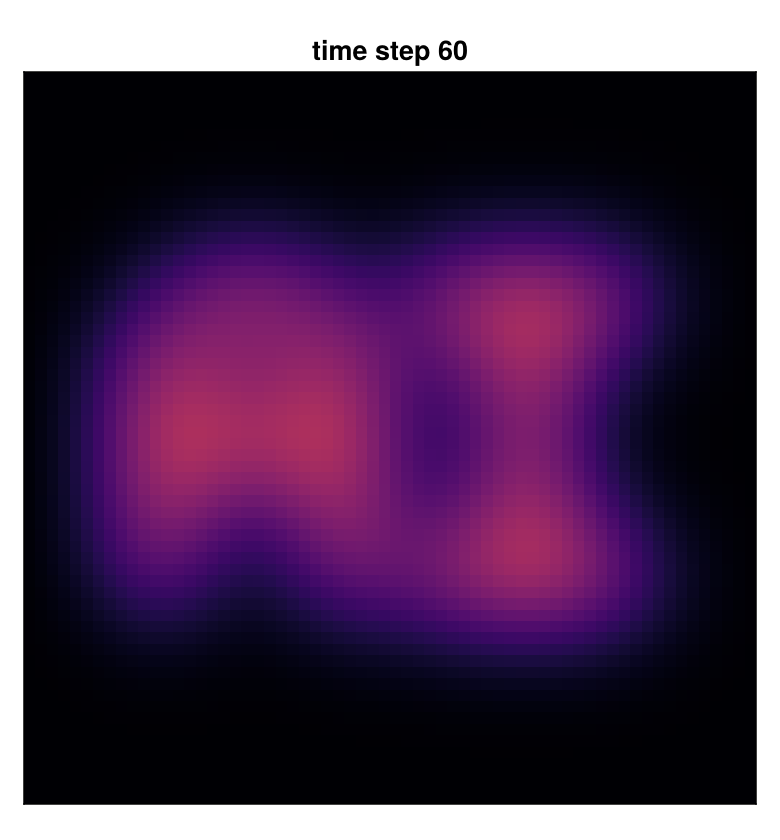

In [5]:
heat_spread!()

We observe only the blurred plate. Which starting pattern caused it? Gradient descent finds it, given the gradient with respect to all 4,096 starting temperatures. `mismatch(u0, observed)` runs `simulate!` from a guess `u0` and measures how far the result is from the observation. Enzyme differentiates it, loops and all, with one line:

```julia
Enzyme.gradient(Reverse, mismatch, u0, Const(observed))     # through all 60 time steps of the loops above
```

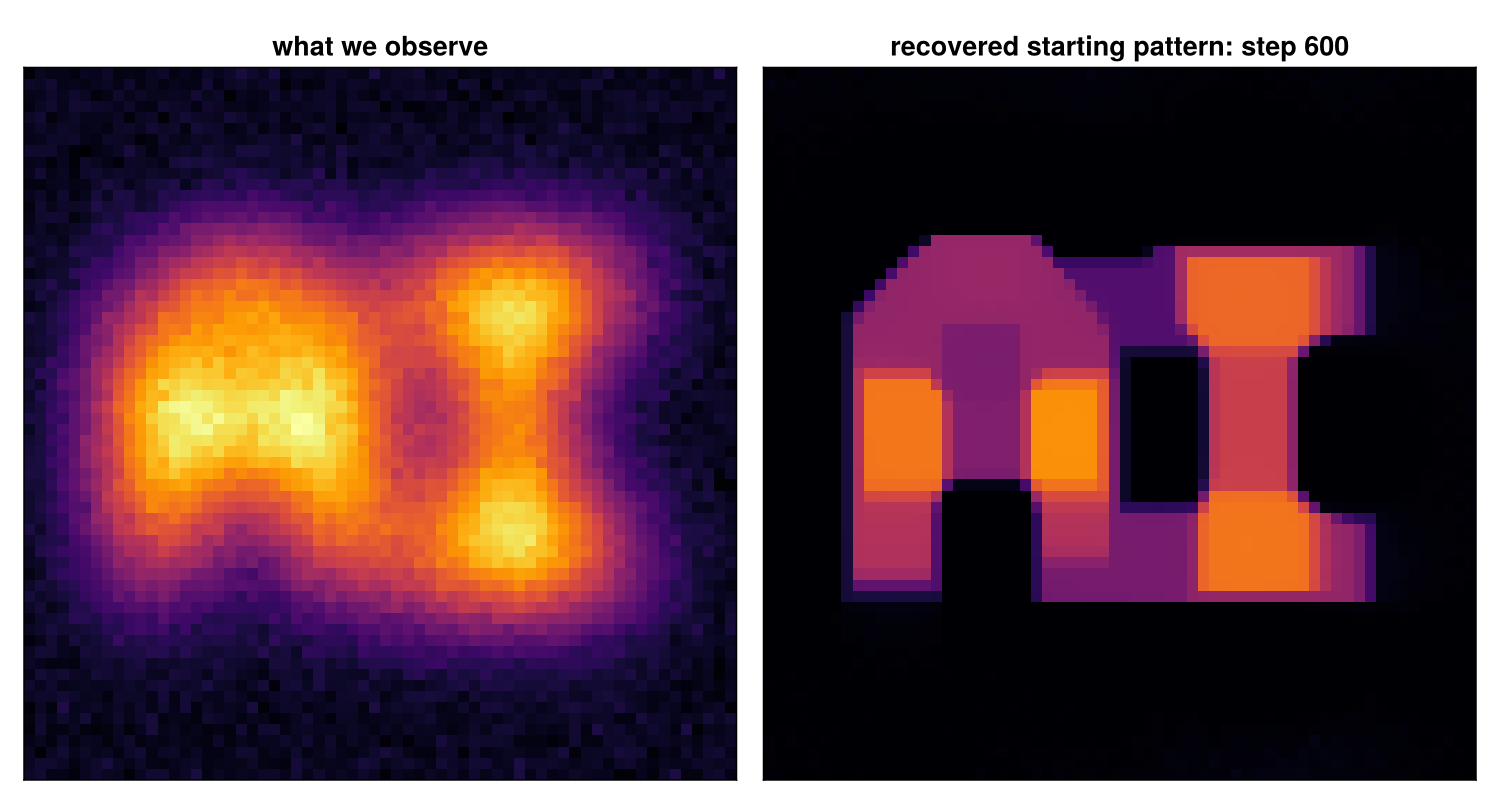

600 gradients through all 60 time steps of the loops: 0.8 s on one CPU core
each gradient costs about as much as 3.8 runs of the simulation


In [6]:
rec = unblur!();

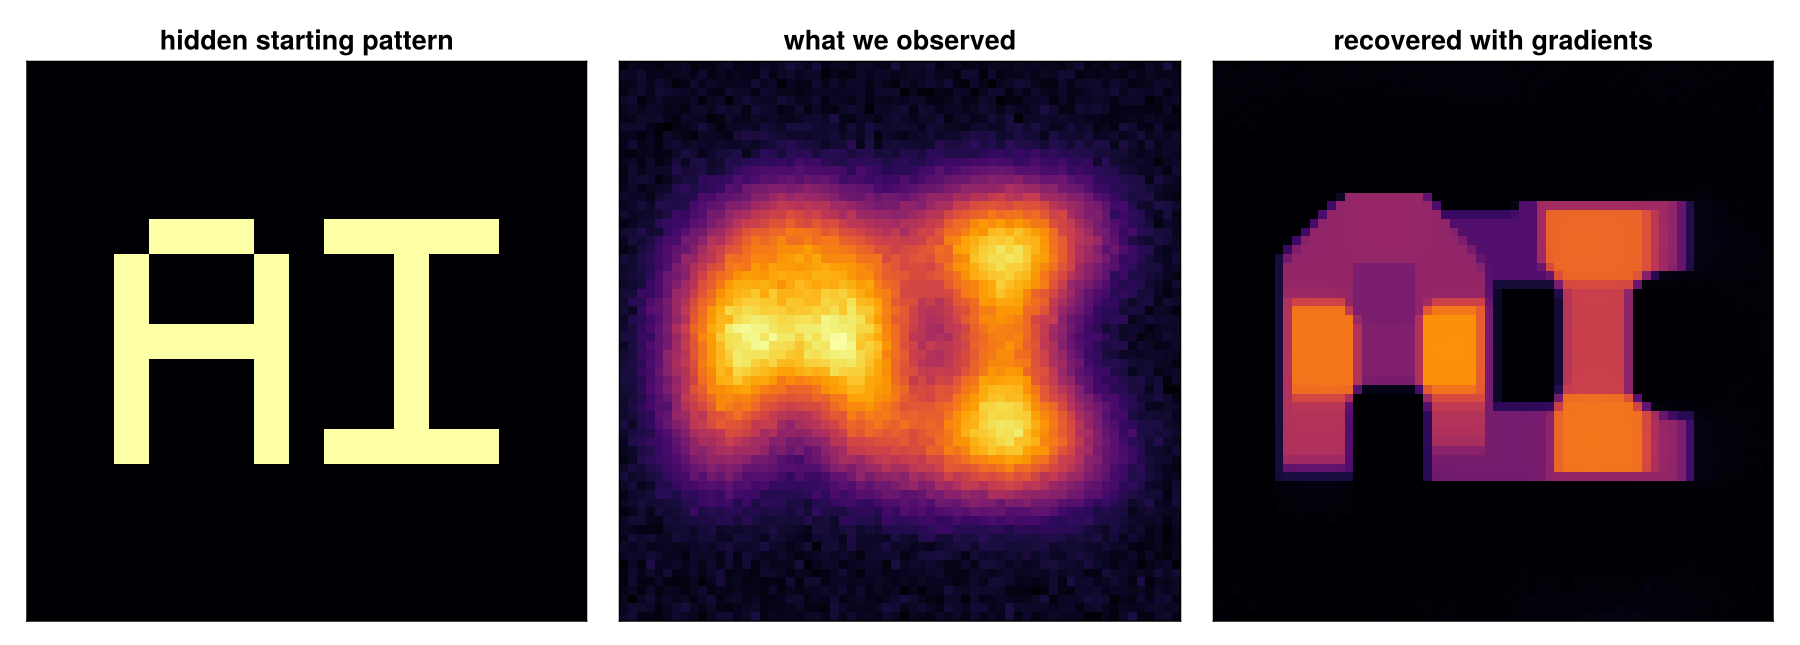

In [7]:
heat_reveal(rec)

Enzyme differentiated the simulation as written, and each gradient cost only a few runs of the simulation. Traditionally, gradients of scientific codes come from a second, hand-written "adjoint" program that experts must write and maintain alongside the simulation; Enzyme derives it from the code itself. The same works at full scale: next, Enzyme differentiates an entire astronomy package.

## Real science: imaging a black hole

In 2019 the **Event Horizon Telescope** (EHT) released the first image of a black hole, M87\*. The EHT links radio dishes across the Earth into one planet-sized telescope, but it never takes a picture: each pair of dishes measures one "ripple pattern" of the sky. Below is **every measurement** from one night in April 2017; the image has to be *inferred* from these points.

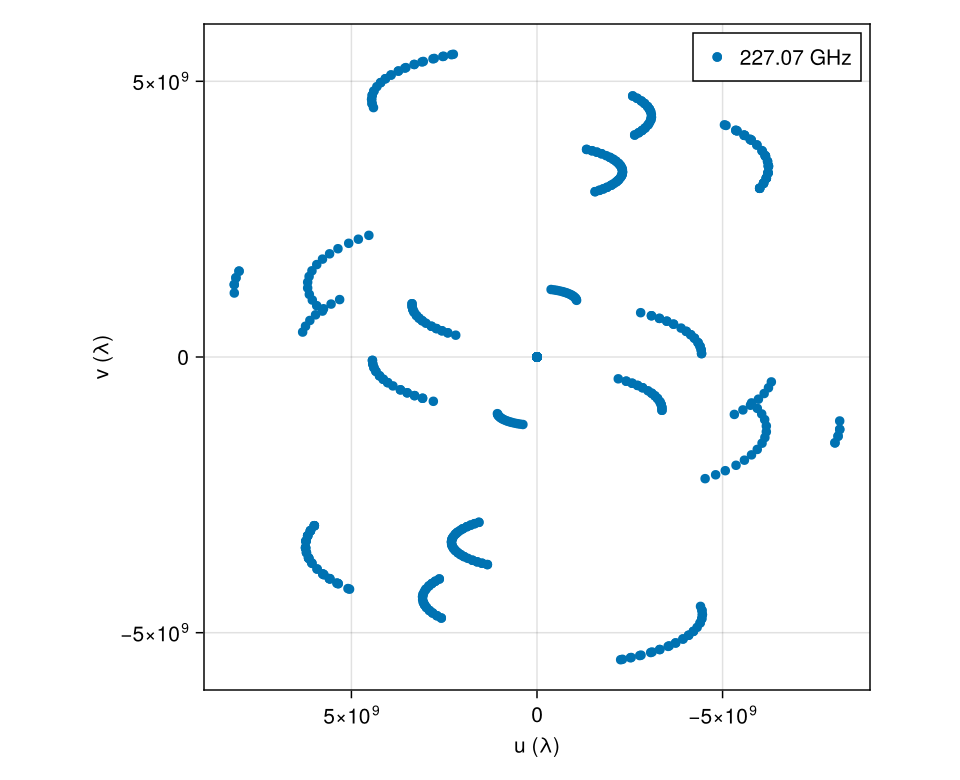

In [8]:
plotfields(dvis, :U, :V; figure_kwargs = (; size = (640, 520)))

[Comrade.jl](https://github.com/ptiede/Comrade.jl) is the EHT imaging package by Paul Tiede. Its model of the sky and of every telescope spans several libraries: **2,635 unknowns from 274 measurements**. Moving a package like this to a GPU, differentiating it, and sampling its uncertainty would each normally take a specialist. Our stack runs it as it is: Reactant compiles it for the GPU, and Enzyme differentiates through all of it.

First, the single best image, by gradient steps through the whole package:

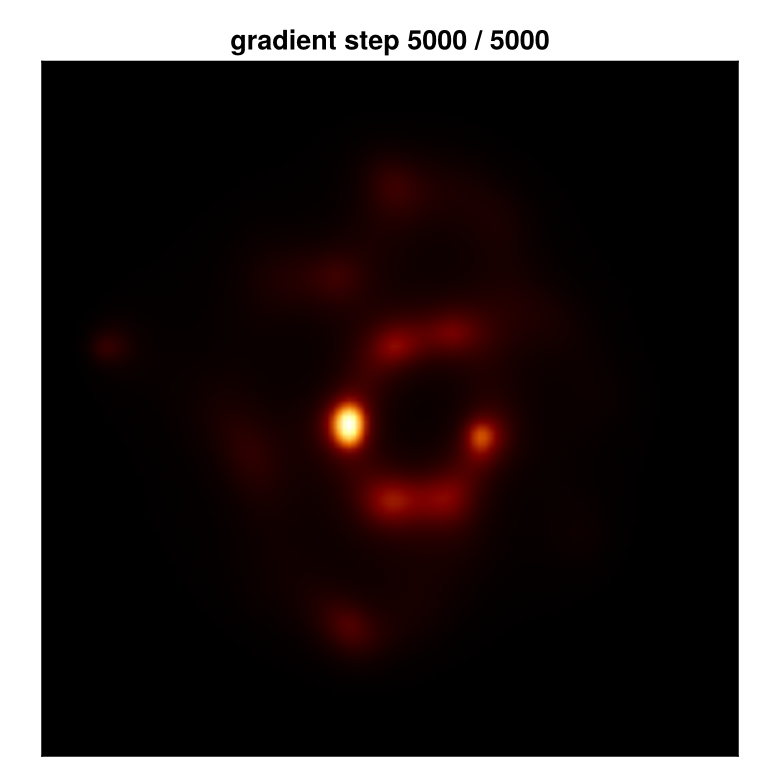

5000 gradient steps on 2635 unknowns: 1.8 s of GPU time


In [9]:
xbest = fit!(steps = 5000);

That is **one** best guess, and it is speckled. Which parts are real? With 2,635 unknowns and 274 measurements, many different images fit the data.

## Impulse: answers with uncertainty

Bayesian inference finds *all* images consistent with the data. In Comrade, switching to our sampler is one argument, and Impulse compiles the entire sampler into one GPU program:

```julia
sample(post, NUTS(0.8), 1000)          # the sampler in Comrade's tutorial
sample(post, ReactantNUTS(), 1000)     # Impulse
```

Paul Tiede's imaging pipeline, [BlackBoxComrade](https://github.com/BH-CAT/BlackBoxComrade.jl), offers the same switch in its configuration (`use_reactant = true`).

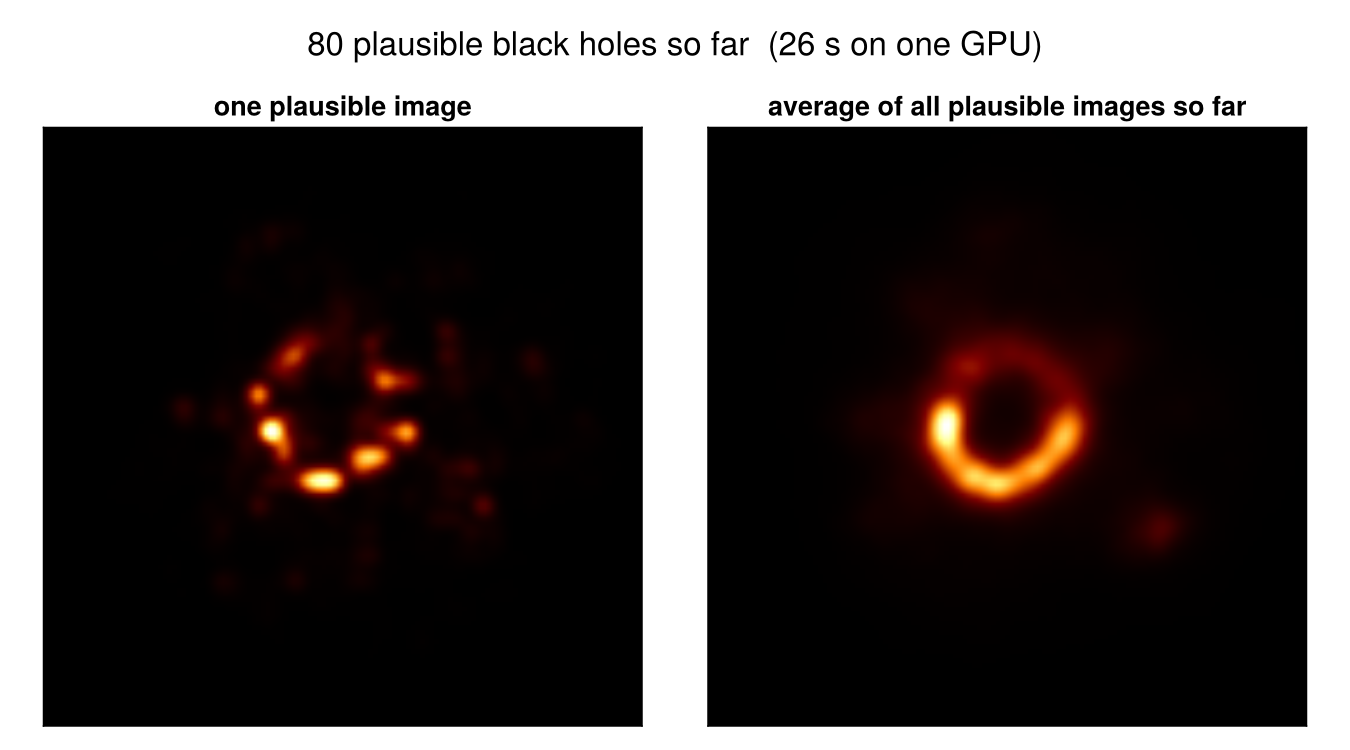

In [10]:
imgs = sample_live!(nchunks = 8);

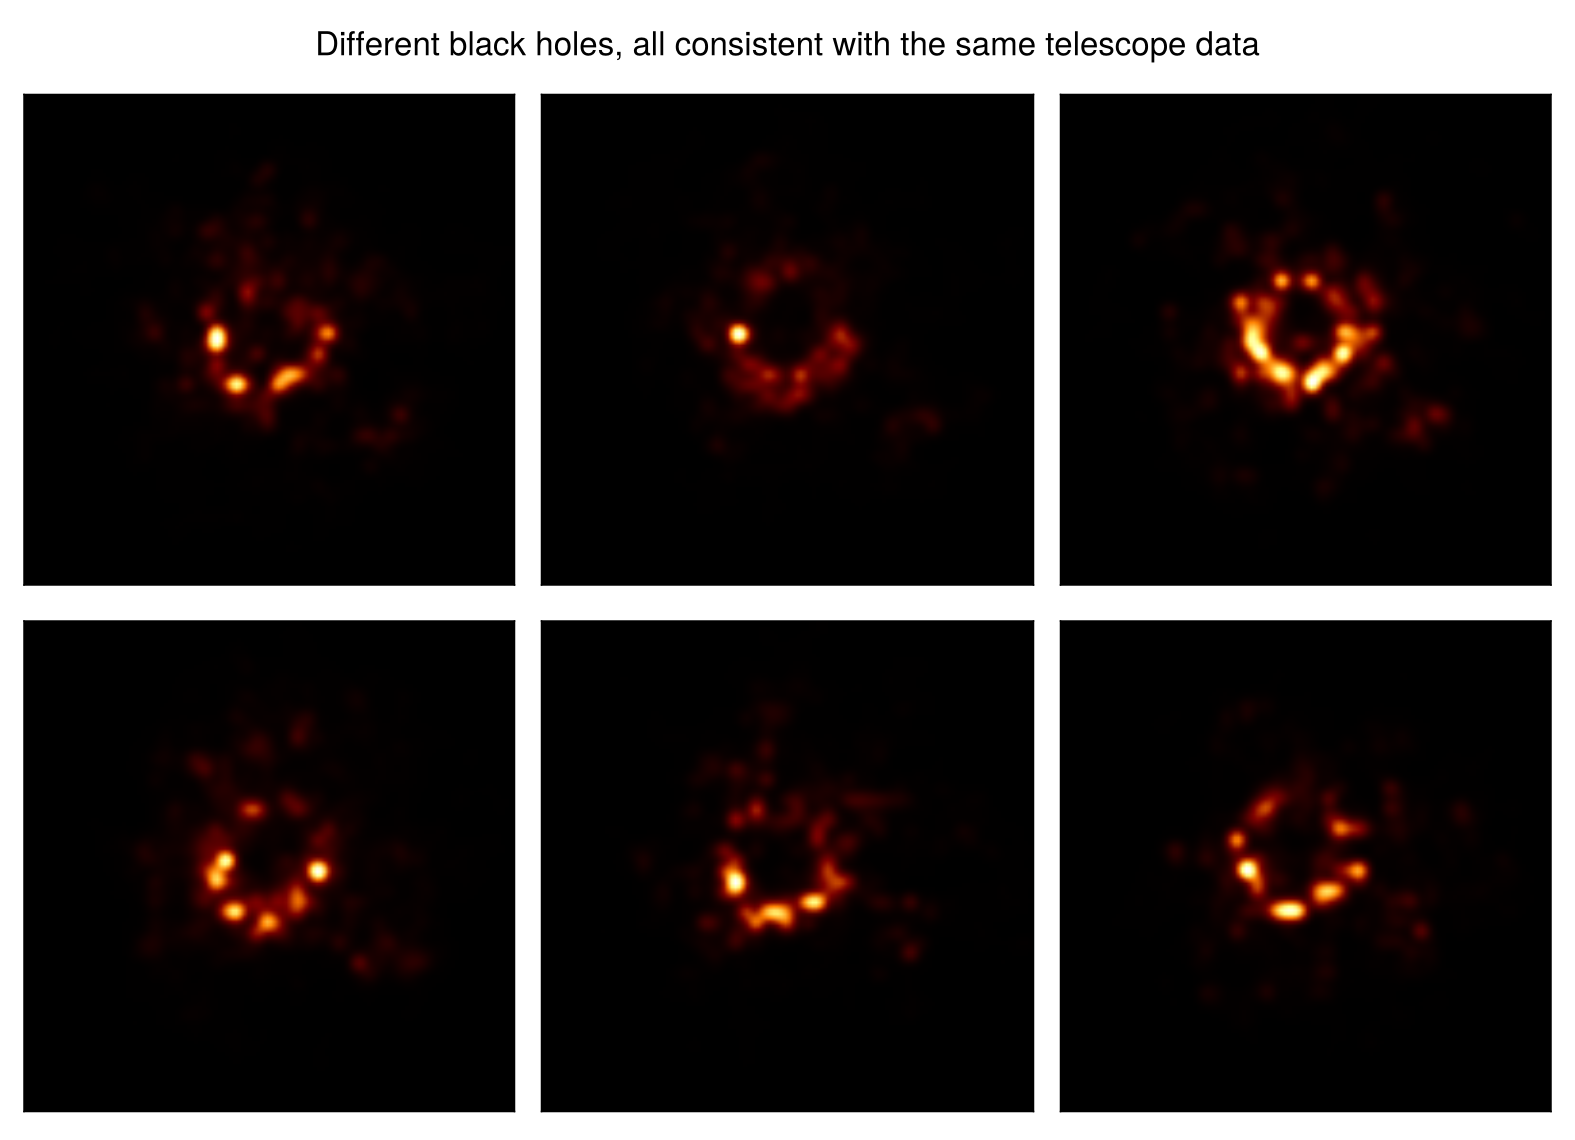

In [11]:
show_draws(imgs)

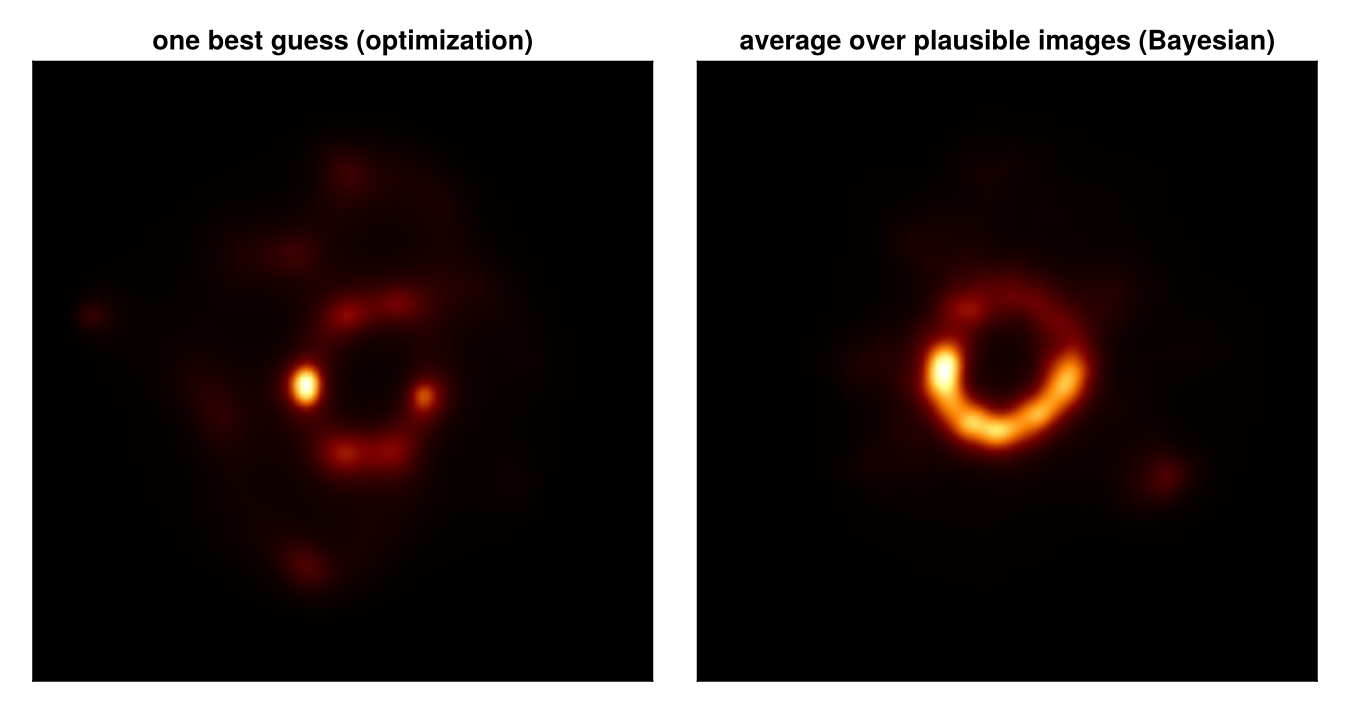

In [12]:
compare(xbest, imgs)

## Impulse: write the textbook model, the compiler makes it fast

Fast inference usually means rewriting the model by hand for performance. Impulse builds probabilistic programming into the compiler, so you write the model the way the textbook writes it and the compiler finds the rewrite.

**A real question:** do primates in bigger social groups have bigger brains? We have 151 species (model m14.10 from McElreath's *Statistical Rethinking*). The catch is that species are not independent data points: close relatives look alike because they share ancestry.

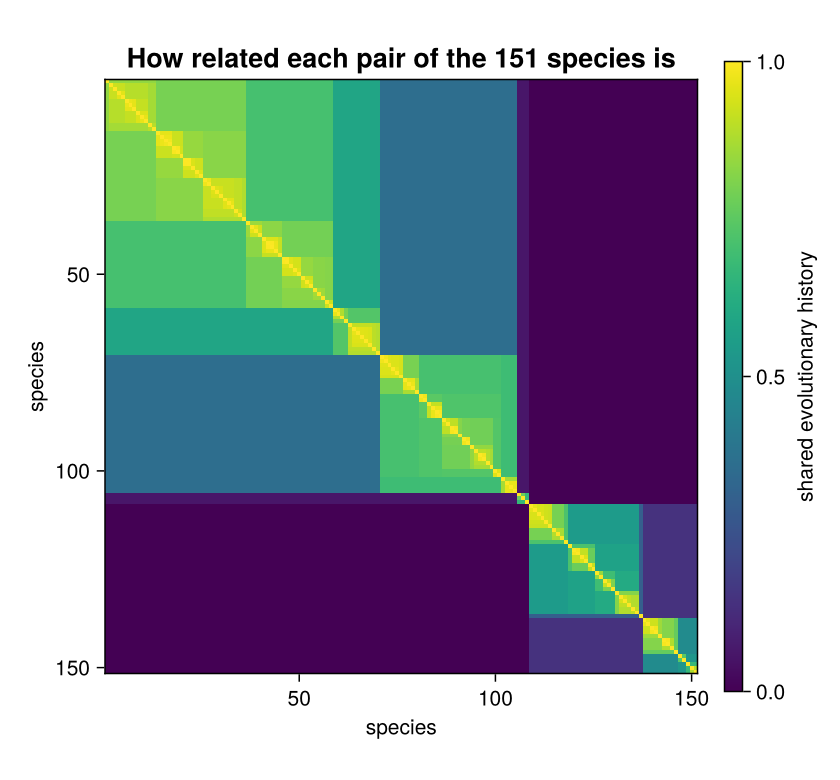

In [13]:
show_family_tree_matrix()

### The model, as the textbook writes it

The same few lines in every framework:

<table><tr><th>Impulse (Julia)</th><th>NumPyro (Python)</th><th>Turing (Julia)</th></tr><tr><td style="vertical-align:top"><pre style="font-size:12px">a  ~ Normal(0.0, 1.0)
bM ~ Normal(0.0, 0.5)
bG ~ Normal(0.0, 0.5)
sigma_sq ~ Exponential(1.0)

mu    = a .+ bM .* M .+ bG .* G
SIGMA = R .* sigma_sq

B ~ MvNormal(mu, SIGMA)</pre></td><td style="vertical-align:top"><pre style="font-size:12px">a  = numpyro.sample(&quot;a&quot;, dist.Normal(0.0, 1.0))
bM = numpyro.sample(&quot;bM&quot;, dist.Normal(0.0, 0.5))
bG = numpyro.sample(&quot;bG&quot;, dist.Normal(0.0, 0.5))
sigma_sq = numpyro.sample(&quot;sigma_sq&quot;, dist.Exponential(1.0))

mu    = a + bM * M + bG * G
SIGMA = R * sigma_sq

numpyro.sample(&quot;B&quot;, dist.MultivariateNormal(mu, SIGMA), obs=B)</pre></td><td style="vertical-align:top"><pre style="font-size:12px">a  ~ Normal(0.0, 1.0)
bM ~ Normal(0.0, 0.5)
bG ~ Normal(0.0, 0.5)
sigma_sq ~ Exponential(1.0)

mu    = a .+ bM .* M .+ bG .* G
SIGMA = R .* sigma_sq

B ~ MvNormal(mu, SIGMA)</pre></td></tr></table>

`SIGMA` is a 151 × 151 matrix. Every evaluation of the model does an expensive computation on `SIGMA`, and inference evaluates the model **thousands of times**.

### To make it fast, an expert rewrites it

`R` never changes, so an expert splits the computation and moves the expensive part out of the inference loop, to run **once**. Stan's documentation recommends exactly this rewrite:

<table><tr><th>textbook</th><th>expert rewrite</th></tr><tr><td style="vertical-align:top"><pre style="font-size:12px">model {
  ...
  SIGMA = R * sigma_sq;
  B ~ multi_normal(mu, SIGMA);
}</pre></td><td style="vertical-align:top"><pre style="font-size:12px">transformed data {
  matrix[N, N] L_R = cholesky_decompose(R);
}
model {
  ...
  B ~ multi_normal_cholesky(mu, sqrt(sigma_sq) * L_R);
}</pre></td></tr></table>

It takes linear-algebra insight, it is easy to get wrong, and the model no longer reads like the science.

### Live: Impulse runs the textbook code

Same model, same data, same sampler. The only difference is whether Impulse's compiler optimizations are on.

compiler optimizations OFF

 … 8.59 s for 1,000 warm-up + 3,000 posterior draws


compiler optimizations ON  … 0.45 s for 1,000 warm-up + 3,000 posterior draws


same code, 19× faster


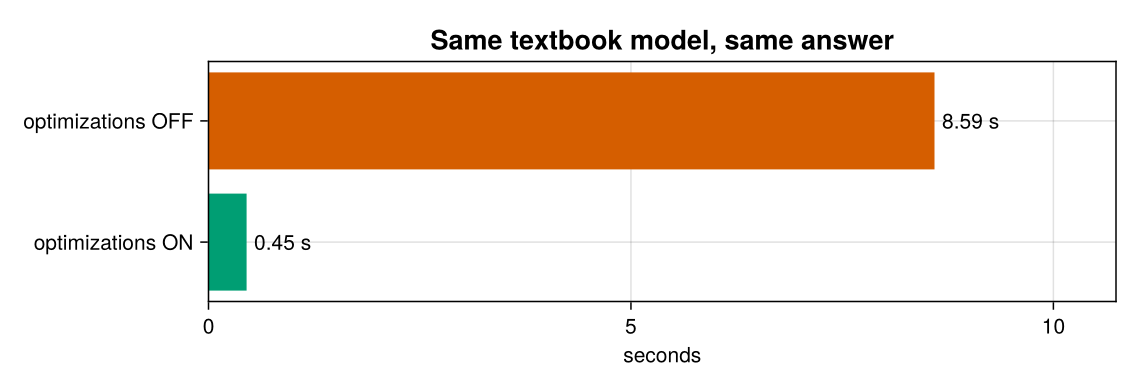

In [14]:
results, fig = race!()
fig

The compiler found the expert's rewrite by itself, **before any inference code existed**: it saw `cholesky(R * sigma_sq)`, rewrote it as `sqrt(sigma_sq) * cholesky(R)`, and moved `cholesky(R)` out of the loop because `R` never changes.

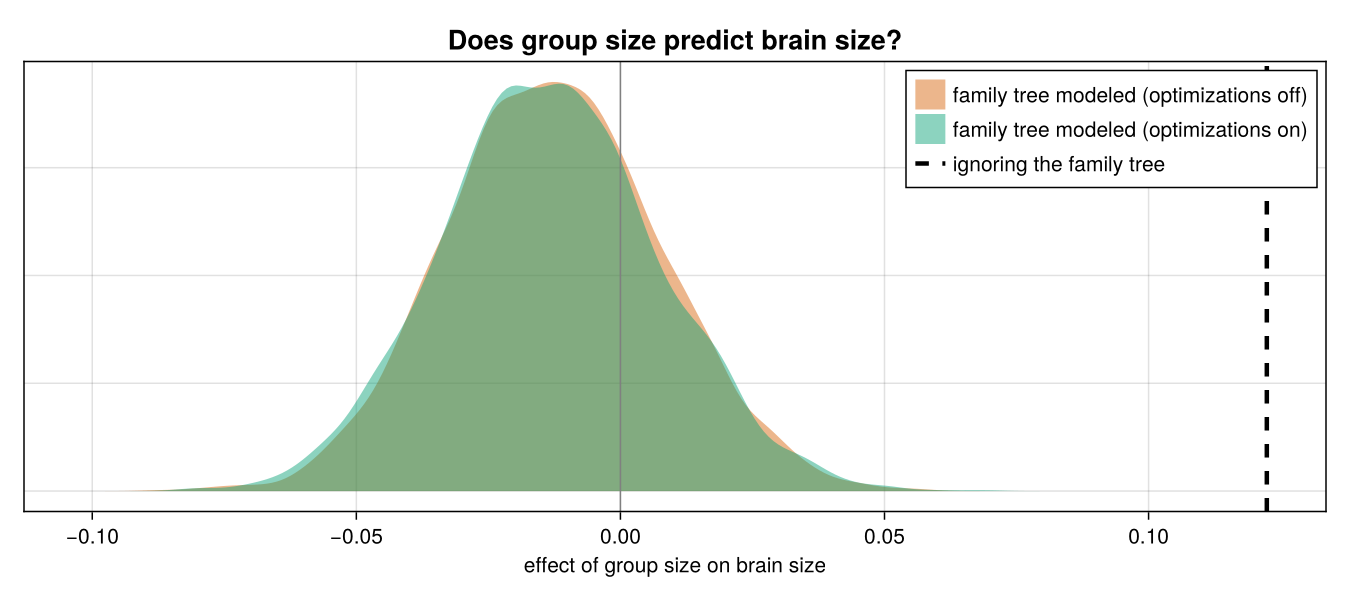

In [15]:
show_answer(results)

Treating species as independent, group size seems to matter. Once shared ancestry is modeled, the effect vanishes: the textbook's conclusion, reproduced in seconds, identical with optimizations on or off.

### Against other frameworks

The same textbook model in each framework, measured in our paper on one CPU core (1,000 warm-up + 3,000 draws). Every framework finds the same answer. NumPyro is built on JAX.

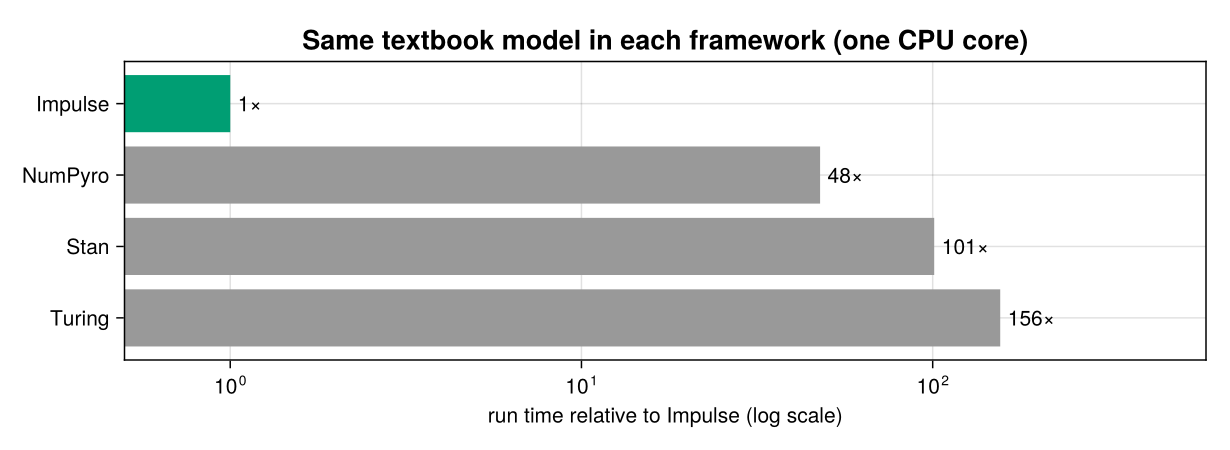

In [16]:
framework_bars()

**How it works.** Impulse makes sampling and inference part of the compiler, so the compiler optimizes the model itself before building the inference algorithm.

## What you saw

- **Reactant:** one line (`@jit`) gives GPU speed without hardware expertise; a real ocean model ran 25 days in about a second by changing one word, and at supercomputer scale the compiler took it to 1,280 Google TPUs and made it 10× to 100× faster on 4,096 GPUs.
- **Enzyme:** gradients of existing simulation code, in the language it is written in: 600 gradients through the whole simulation in about a second, and an entire astronomy package differentiated, with no rewrite.
- **Real science:** the EHT's imaging package, compiled, differentiated, and sampled with uncertainty, live.
- **Impulse:** the compiler did an expert's rewrite of a textbook model by itself: about 20× faster, and 48×, 101× and 156× faster than NumPyro, Stan and Turing.

## Try it

```julia
] add Reactant Enzyme
using Reactant, Enzyme
x = Reactant.to_rarray(data)              # your data, on the GPU or TPU
@jit f(x)                                 # your function, compiled
@jit Enzyme.gradient(Reverse, f, x)       # its gradient
```

Bring us a model whose code is too slow, too hard to differentiate, or that needs uncertainty.

| | |
|---|---|
| Reactant.jl | https://github.com/EnzymeAD/Reactant.jl |
| Probabilistic programming (Impulse) tutorial | https://enzymead.github.io/Reactant.jl/stable/tutorials/probprog/ |
| Enzyme (C, C++, Fortran, Rust, Julia, Python/JAX, ...) | https://enzyme.mit.edu |
| Comrade.jl (black-hole imaging) | https://github.com/ptiede/Comrade.jl |
| BlackBoxComrade (EHT imaging pipeline) | https://github.com/BH-CAT/BlackBoxComrade.jl |
| Hands-on workshop notebook (Lux + Reactant) | https://colab.research.google.com/drive/1UobcFjfwDI3N2EXvH3KbRS5ZxY9Riy4y |